# Dar_001 — P1 Moon temperature versus lunar local time

**Question:** How do observed phase-average surface temperatures vary with lunar local time,
region and seasonal phase, and how much does a fixed-cell comparison change the picture on matching products?

**Data:** D01, all 144 south-polar Diviner PCP table/XML pairs (240 m native centers),
2009-07-05 to 2020-03-15 cumulative observations. D05's original seven SDEM ZIPs define
the same region rectangles used in notebooks 06/25. ZIPs are not extracted or modified.

**References:** [06 preprocessing](06_diviner_temperature.ipynb),
[25 support EDA](../Environmental_Context/25_environment_native_support_eda.ipynb),
[P1 register](../../../Critical_Project_Dataset.md#p1--core-environmental-datasets),
[EDA plan](../../EDA_Notes.md#todo--moon-environmental-eda).
The original label-driven reader, CRS, validity rules and half-open region bounds are reused.
This new notebook does not require the unfinished 05/13 terrain pipeline.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'outline.md').is_file() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the repository or its subfolders')
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'darrel stuff/EDA'))
DATA_ROOT = ROOT / 'darrel stuff/data'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from moon_p1_analysis import (region_footprints, local_time_hours, prepare_regional_diviner,
    temperature_summary, documented_illumination, sample_containing_pixels, native_window)
import moon_p1_analysis
def short(name):
    return name.split('_', 2)[-1].replace('_', ' ')
def save_figure(run, fig, name):
    fig.savefig(run.path(name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)
print('Read-only raw inputs:', DATA_ROOT)

Read-only raw inputs: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data


## 1. Selection and units

Default is the full collection. `PREPARED_RUN_ID` pins the explicit, previously completed regional exports used for this execution. Their output hashes and selections are verified; upstream raw-source hashes remain in that prior provenance. Set it to `None` to rebuild directly from raw tables. `FILE_LIMIT = 1` with `PREPARED_RUN_ID = None` is an explicitly labelled **pilot**, useful
for validating the workflow, not a substitute for the full result. Missing temperature rows,
missing phases and invalid local times are counted, never filled. XML requires `ltim` in
hours and `tbol` in K. Raw local hours must be in `[0, 24]`. The exact `24.0` endpoint is normalized to `0.0`
(midnight), with raw `ltim` retained and the conversion counted. Other out-of-range values
are rejected, never arbitrarily wrapped.

In [2]:
FILE_LIMIT = None
# Set None to rebuild directly from raw tables; otherwise verify this explicit prepared run.
PREPARED_RUN_ID = '20261106T081135919918Z_54e79b'
CHUNK_ROWS = 250_000
labels = sorted((DATA_ROOT / 'moon/diviner/seasonal').glob('pcp_avg_tbol_pols_ls*_slon*_240.xml'))
if len(labels) != 144:
    raise ValueError(f'Expected all 144 source labels; found {len(labels)}')
if FILE_LIMIT is not None:
    if not isinstance(FILE_LIMIT, int) or not 1 <= FILE_LIMIT <= len(labels):
        raise ValueError('FILE_LIMIT must be None or an integer from 1 to 144')
    labels = labels[:FILE_LIMIT]
regions = region_footprints(DATA_ROOT)
SCOPE = 'full 144-product collection' if len(labels) == 144 else f'pilot: {len(labels)} products'
print(SCOPE, '| original regions:', len(regions))
display(pd.DataFrame([{'region': name, 'bounds_m': info['bounds'], 'archive': info['archive'].name}
                      for name, info in regions.items()]))

full 144-product collection | original regions: 7


,region,bounds_m,archive
0,A3CLR22_10_Leibnitz_Beta_Plateau,"(65000.0, 110000.0, 81000.0, 126000.0)",A3CLR22_10_Leibnitz_Beta_Plateau.zip
1,A3CLR22_11_Malapert_Massif,"(-11000.0, 111000.0, 10000.0, 132000.0)",A3CLR22_11_Malapert_Massif.zip
2,A3CLR22_12_deGerlache_Kocher_Massif,"(-123400.0, -66100.0, -103400.0, -46100.0)",A3CLR22_12_deGerlache_Kocher_Massif.zip
3,A3CLR22_2_Haworth,"(-52900.0, 75600.0, -23100.0, 105400.0)",A3CLR22_2_Haworth.zip
4,A3CLR22_3_Faustini_Rim_A,"(54000.0, -10000.0, 74000.0, 10000.0)",A3CLR22_3_Faustini_Rim_A.zip
5,A3CLR22_4_deGerlache_Rim_2,"(-58500.0, 13000.0, -38500.0, 33000.0)",A3CLR22_4_deGerlache_Rim_2.zip
6,A3CLR22_5_Connecting_Ridge_Extension,"(-38700.0, -16100.0, -18700.0, 3900.0)",A3CLR22_5_Connecting_Ridge_Extension.zip


## 2. Analysis definitions

- One row is a source native center **in one phase product**, not an independent exposure.
- Report 1-hour bins by region **and Ls**; show counts and missing hours beside quantiles.
- Compute products with usable rows in all regions from this selection (no hard-coded 17).
- Sensitivity cohort: within each region, retain only centers with usable rows in every
  common product. Export its exclusions, including regions with no complete cohort. Sensitivity compares `common_available` against `complete_common` on the **same common products**, Ls and hour bins; it never compares 144-product availability to a 17-product fixed subset.
- Do not join the first and last plotted bins with an unsupported interpolated curve.

In [3]:
def analyse_local_time(observations, coverage):
    observations = observations.copy()
    observations['local_time_h'] = local_time_hours(observations.ltim)
    observations['local_time_bin_h'] = np.floor(observations.local_time_h)
    observations['usable'] = observations.valid_temperature & observations.local_time_h.notna()
    presence = coverage.pivot(index='region', columns='source_product', values='usable_rows').gt(0)
    common = presence.columns[presence.all(axis=0)].tolist()
    cohort_rows = []
    observations['complete_common_cohort'] = False
    for region, part in observations.groupby('region', sort=True):
        valid = part.loc[part.usable & part.source_product.isin(common)]
        counts = valid.groupby(['clon', 'clat']).source_product.nunique()
        complete = counts.index[counts == len(common)] if common else pd.MultiIndex.from_tuples([], names=['clon', 'clat'])
        keys = pd.MultiIndex.from_frame(part[['clon', 'clat']])
        flag = keys.isin(complete)
        observations.loc[part.index, 'complete_common_cohort'] = flag
        cohort_rows.append({'region': region, 'observed_centers': len(keys.unique()),
            'common_products': len(common), 'complete_centers': len(complete),
            'status': 'available' if len(complete) else 'no_complete_common_cohort'})
    groups = ['region', 'seasonal_ls_bin', 'local_time_bin_h']
    summaries = []
    for cohort, part in [('available', observations),
                         ('common_available', observations.loc[observations.source_product.isin(common)]),
                         ('complete_common', observations.loc[observations.complete_common_cohort
                                                               & observations.source_product.isin(common)])]:
        summary = temperature_summary(part, groups)
        summary['cohort'] = cohort
        summaries.append(summary)
    populated = [part for part in summaries if len(part)]
    if not populated:
        raise ValueError('No usable temperature/local-time pairs in the selected region products')
    summary = pd.concat(populated, ignore_index=True)
    # Reindex all hours so absent bins remain explicit NaN, with zero observed rows.
    index = pd.MultiIndex.from_product([sorted(observations.region.unique()),
        sorted(observations.seasonal_ls_bin.unique()), range(24), ['available', 'common_available', 'complete_common']],
        names=[*groups, 'cohort'])
    summary = summary.set_index([*groups, 'cohort']).reindex(index).reset_index()
    summary[['rows', 'native_centers']] = summary[['rows', 'native_centers']].fillna(0).astype(int)
    return observations, summary, pd.DataFrame(cohort_rows), common

def plot_local_time(run, summary):
    fig, axes = plt.subplots(3, 3, figsize=(16, 12), layout='constrained')
    for ax, region in zip(axes.flat, regions):
        part = summary.loc[(summary.region == region) & (summary.cohort == 'available')]
        for ls, group in part.groupby('seasonal_ls_bin'):
            ax.plot(group.local_time_bin_h + .5, group.median_K, marker='.', label=f'Ls {ls:03d}')
            ax.fill_between(group.local_time_bin_h + .5, group.q10_K, group.q90_K, alpha=.08)
        ax.set(title=short(region), xlabel='Lunar local hour (cyclic)', ylabel='Phase-average brightness temperature (K)', xlim=(0,24))
        ax.grid(alpha=.2)
    for ax in list(axes.flat)[len(regions):]: ax.set_visible(False)
    axes.flat[0].legend(fontsize=7, ncol=2)
    fig.suptitle(f'Temperature versus local time: medians and 10–90% spatial quantiles\n{SCOPE}; absent bins remain gaps')
    save_figure(run, fig, 'temperature_local_time')
    available = summary.loc[summary.cohort == 'available'].groupby(['region','local_time_bin_h']).rows.sum().unstack().reindex(regions)
    fig, ax = plt.subplots(figsize=(12,5), layout='constrained')
    im = ax.imshow(np.log10(available.to_numpy() + 1), aspect='auto', cmap='viridis')
    ax.set(xticks=range(24), xlabel='Local-hour bin start', title='Sampling support: log10(usable center–product rows + 1)')
    ax.set_yticks(range(len(regions)), [short(r) for r in regions])
    fig.colorbar(im, ax=ax, label='Log10 count + 1 (not independent cells)')
    save_figure(run, fig, 'local_time_coverage')
    fixed = summary.loc[summary.cohort == 'complete_common'].drop(columns='cohort')
    paired = summary.loc[summary.cohort == 'common_available'].merge(fixed, on=['region','seasonal_ls_bin','local_time_bin_h'], suffixes=('_available','_fixed'), validate='one_to_one')
    paired['fixed_minus_available_median_K'] = paired.median_K_fixed - paired.median_K_available
    paired.to_csv(run.path('cohort_sensitivity.csv'), index=False)
    fig, ax = plt.subplots(figsize=(10,5), layout='constrained')
    for region, group in paired.groupby('region'):
        ax.scatter(group.local_time_bin_h + .5, group.fixed_minus_available_median_K, s=14, alpha=.55, label=short(region))
    ax.axhline(0, color='black', linewidth=.8)
    ax.set(xlabel='Lunar local hour', ylabel='Fixed minus common-available median (K)', title='Fixed-cell sensitivity: matched common products, local hour and Ls')
    ax.legend(fontsize=7); ax.grid(alpha=.2)
    save_figure(run, fig, 'cohort_sensitivity')

## 3. Run, plot and save traceable findings

With `PREPARED_RUN_ID=None`, this reads the selected raw collection once, in chunks and may take several minutes. An explicit prepared run reuses only verified regional exports, not its previous analysis summaries. Derived local-time support is recomputed from retained raw `ltim`.
All new outputs go to an isolated `data/processed/analysis/dar_001_temperature_local_time/`
run. The provenance records source hashes, selection, notebook and reader code. Raw
archives, tables, earlier notebooks and existing processing runs remain untouched.

Accepted local analysis/dar_001_temperature_local_time run: 20261106T081135919918Z_54e79b


Reanalysing verified prepared rows from: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_001_temperature_local_time\20261106T081135919918Z_54e79b


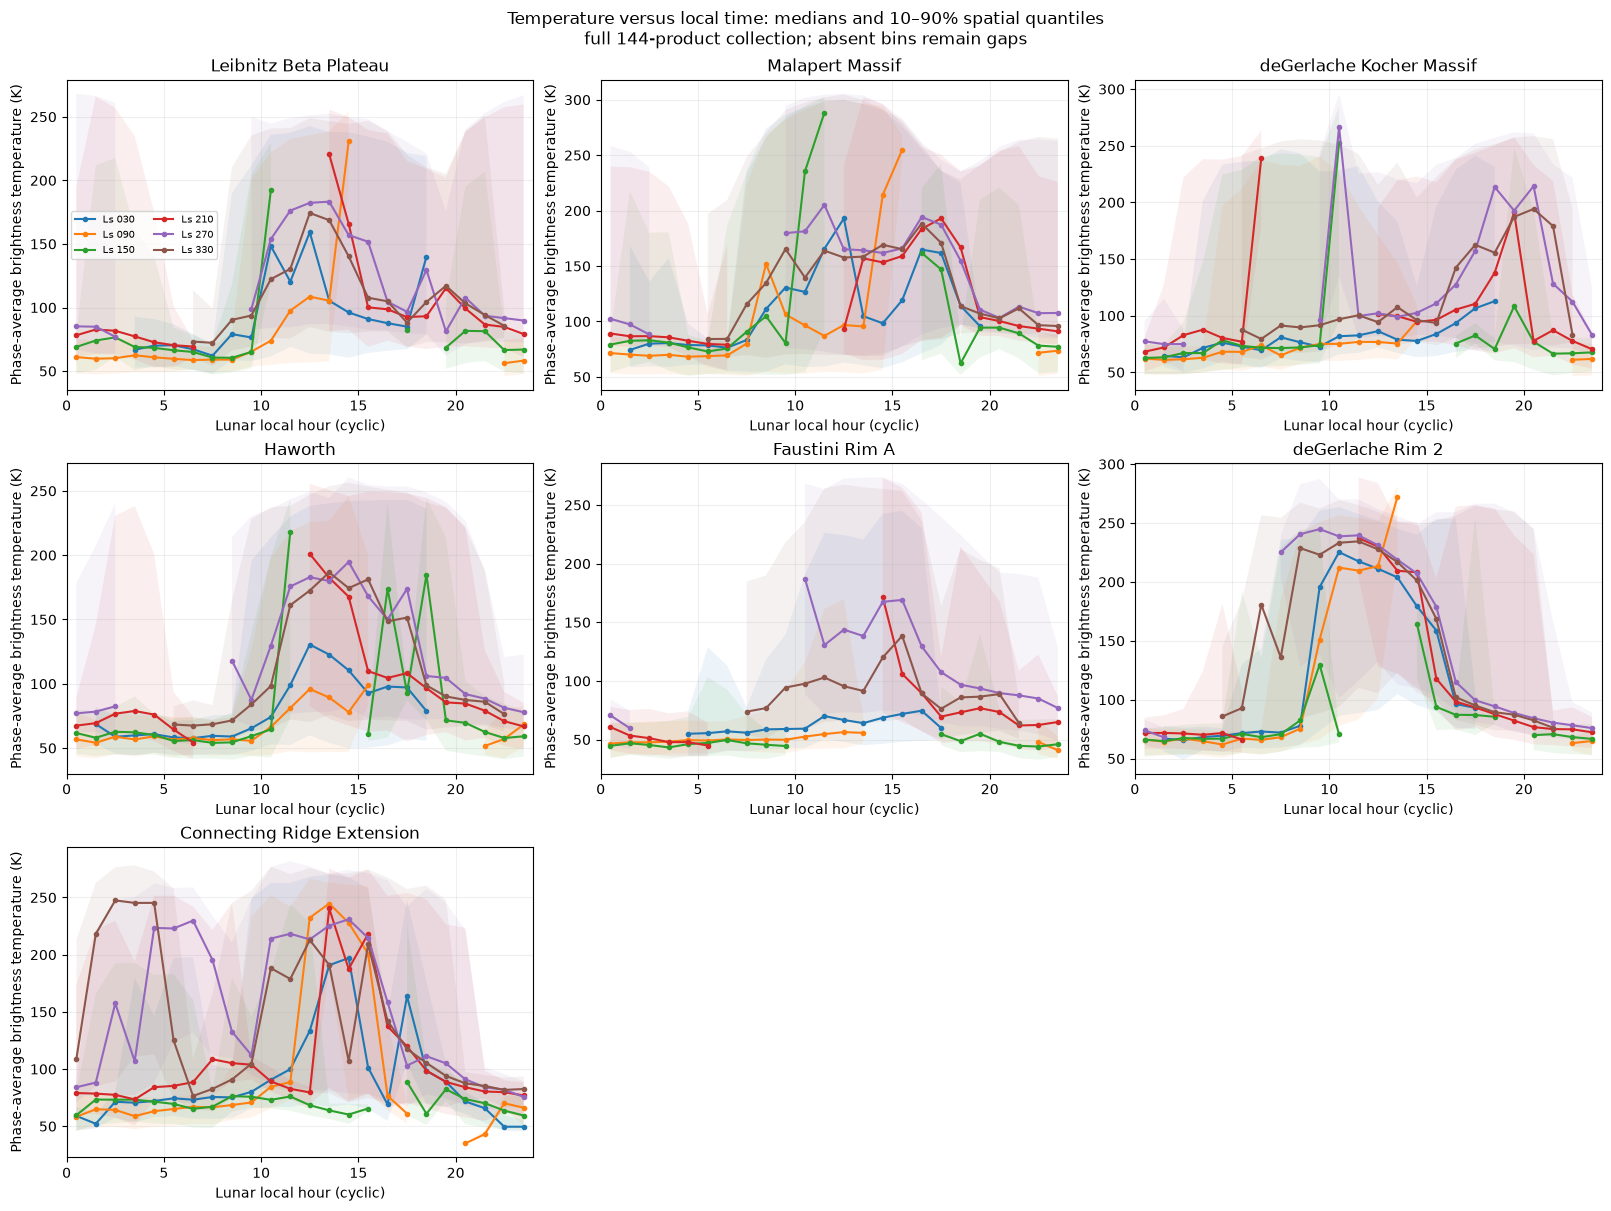

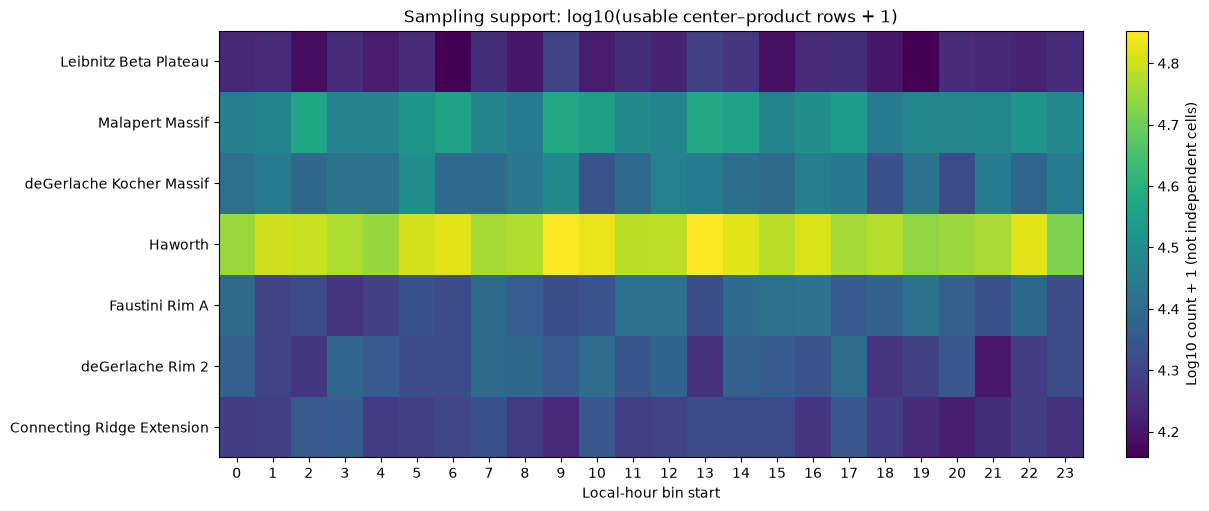

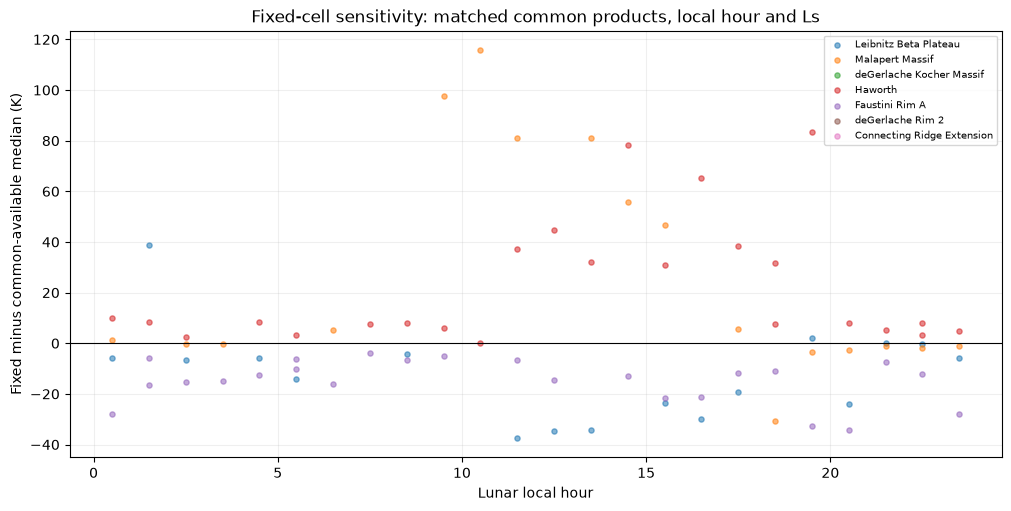

,region,observed_centers,common_products,complete_centers,status
0,A3CLR22_10_Leibnitz_Beta_Plateau,4422,17,84,available
1,A3CLR22_11_Malapert_Massif,7569,17,6051,available
2,A3CLR22_12_deGerlache_Kocher_Massif,6972,17,0,no_complete_common_cohort
3,A3CLR22_2_Haworth,15500,17,2510,available
4,A3CLR22_3_Faustini_Rim_A,6972,17,15,available
5,A3CLR22_4_deGerlache_Rim_2,6889,17,0,no_complete_common_cohort
6,A3CLR22_5_Connecting_Ridge_Extension,7056,17,0,no_complete_common_cohort


,region,seasonal_ls_bin,local_time_bin_h,cohort,rows,native_centers,median_K,q10_K,q90_K
9,A3CLR22_10_Leibnitz_Beta_Plateau,30,3,available,4365,4365,66.717987,52.776801,92.758346
12,A3CLR22_10_Leibnitz_Beta_Plateau,30,4,available,4411,4411,70.010292,52.901066,90.885826
15,A3CLR22_10_Leibnitz_Beta_Plateau,30,5,available,4372,4372,70.315746,54.130922,86.902130
18,A3CLR22_10_Leibnitz_Beta_Plateau,30,6,available,4326,4326,67.169666,50.822351,79.268410
21,A3CLR22_10_Leibnitz_Beta_Plateau,30,7,available,4422,4422,62.087219,48.052045,70.934777
24,A3CLR22_10_Leibnitz_Beta_Plateau,30,8,available,4392,4392,79.064385,58.459697,190.063458
27,A3CLR22_10_Leibnitz_Beta_Plateau,30,9,available,4422,4422,76.419712,57.925103,211.724874
30,A3CLR22_10_Leibnitz_Beta_Plateau,30,10,available,2884,2884,148.292077,61.383325,235.784637
33,A3CLR22_10_Leibnitz_Beta_Plateau,30,11,available,4422,4422,120.350716,69.007459,237.400139
34,A3CLR22_10_Leibnitz_Beta_Plateau,30,11,common_available,4422,4422,120.350716,69.007459,237.400139


**Executed scope:** full 144-product collection. **Usable rows:** 4,825,369; **common phase products:** 17; **regions with a complete fixed cohort:** 4/7.

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_001_temperature_local_time\20261106T082643415392Z_4e6a0b


In [4]:
config = {'scope': SCOPE, 'products': len(labels), 'local_time_bin_hours': 1,
          'regions': list(regions), 'native_support_m': 240, 'prepared_run_id': PREPARED_RUN_ID,
          'comparison': 'region/Ls/hour; fixed common-product cohort sensitivity',
          'temperature': 'cumulative phase-average surface bolometric brightness temperature, K'}
with Run(ROOT, 'analysis/dar_001_temperature_local_time', config,
         'Moon/Thermal/Dar_001_temperature_local_time.ipynb') as run:
    run.input(Path(moon_p1_analysis.__file__))
    for info in regions.values(): run.input(info['archive'])
    if PREPARED_RUN_ID is None:
        observations, coverage = prepare_regional_diviner(labels, regions, run, CHUNK_ROWS)
    else:
        from notebooks.shared.inspection import verify_run, check_input
        prepared = latest_completed_run(ROOT, 'analysis/dar_001_temperature_local_time', PREPARED_RUN_ID)
        expected = verify_run(prepared)
        run.input(prepared / 'provenance.json')
        def prepared_input(relative):
            path = prepared / relative
            check_input(path, expected, {})
            run.input(path)
            return path
        old_bounds = json.loads(prepared_input('region_footprints.json').read_text(encoding='utf-8'))
        if set(old_bounds) != set(regions) or any(tuple(old_bounds[k]['bounds_m']) != regions[k]['bounds'] for k in regions):
            raise ValueError('Prepared region selection differs; rebuild from raw tables')
        coverage = pd.read_csv(prepared_input('product_coverage.csv'))
        if set(coverage.source_product) != {p.stem for p in labels} or set(coverage.region) != set(regions):
            raise ValueError('Prepared product/region selection differs; rebuild from raw tables')
        observations = pd.concat([pd.read_csv(prepared_input(f'regional_observations/{region}.csv.gz'))
                                  for region in regions], ignore_index=True)
        if observations.valid_temperature.dtype != bool:
            raise ValueError('Prepared validity flags must be booleans')
        if len(observations) != coverage.selected_rows.sum():
            raise ValueError('Prepared row count disagrees with its coverage table')
        print('Reanalysing verified prepared rows from:', prepared)
    # Recompute derived local-time support from retained raw ltim, including exact 24h endpoints.
    observations['local_time_h'] = local_time_hours(observations.ltim)
    support = observations.assign(valid_local_time_rows=observations.local_time_h.notna(),
        usable_rows=observations.valid_temperature & observations.local_time_h.notna())
    counts = support.groupby(['region','source_product'])[['valid_local_time_rows','usable_rows']].sum().reset_index()
    coverage = coverage.drop(columns=['valid_local_time_rows','usable_rows']).merge(
        counts, on=['region','source_product'], how='left', validate='one_to_one')
    coverage[['valid_local_time_rows','usable_rows']] = coverage[['valid_local_time_rows','usable_rows']].fillna(0).astype(int)
    observations, summary, cohorts, common_products = analyse_local_time(observations, coverage)
    coverage.to_csv(run.path('product_coverage.csv'), index=False)
    summary.to_csv(run.path('local_time_temperature.csv'), index=False)
    cohorts.to_csv(run.path('cohort_coverage.csv'), index=False)
    for region, part in observations.groupby('region'):
        part.to_csv(run.path(f'regional_observations/{region}.csv.gz'), index=False,
                    compression={'method':'gzip', 'mtime':0, 'compresslevel':3})
    bounds = {name: {'bounds_m': info['bounds'], 'archive': str(info['archive'].relative_to(ROOT)),
                     'member': info['member']} for name, info in regions.items()}
    run.path('region_footprints.json').write_text(json.dumps(bounds, indent=2), encoding='utf-8')
    assert len(coverage) == len(regions) * len(labels)
    assert not observations.duplicated(['region','source_product','clon','clat']).any()
    assert summary.loc[summary.rows.eq(0), 'median_K'].isna().all()
    plot_local_time(run, summary)
    usable = observations.loc[observations.usable]
    findings = {'scope': SCOPE, 'observed_rows': len(observations), 'usable_rows': len(usable),
        'invalid_temperature_rows': int((~observations.valid_temperature).sum()),
        'invalid_local_time_rows': int(observations.local_time_h.isna().sum()),
        'exact_24h_rows_normalized_to_midnight': int(observations.ltim.eq(24).sum()),
        'empty_region_product_pairs': int(coverage.selected_rows.eq(0).sum()),
        'common_products': common_products, 'complete_cohort_regions': int(cohorts.complete_centers.gt(0).sum()),
        'usable_temperature_quantiles_K': usable.tbol.quantile([.1,.5,.9]).to_dict(),
        'limits': ['Phase averages, not chronological mission temperatures or extrema',
                   'Repeated native centers; quantiles are not confidence intervals',
                   'No equipment thresholds, suitability labels or algorithm weights inferred']}
    run.path('findings.json').write_text(json.dumps(findings, indent=2), encoding='utf-8')
    display(cohorts)
    display(summary.loc[summary.rows.gt(0)].head(20))
    display(Markdown(f"**Executed scope:** {SCOPE}. **Usable rows:** {len(usable):,}; "
                     f"**common phase products:** {len(common_products)}; "
                     f"**regions with a complete fixed cohort:** {findings['complete_cohort_regions']}/{len(regions)}."))
OUT = run.directory
print('Completed:', OUT)

## 4. Relevance to Stage 3 and limitations

The exported region/Ls/hour counts and quantiles help select a defensible thermal evidence
cohort and expose missingness before environmental checks. Fixed-cohort sensitivity shows
how changing observed cells can alter a comparison. Missing local-time bins remain **Unknown**. Zero invalid temperature rows does not establish full coverage: the source tables omit empty bins, and `product_coverage.csv` separately records region/products with no selected rows.

Surface brightness temperature is not air temperature, component temperature, a continuous
exposure history or a mission maximum/minimum. These descriptive correlations do not provide
equipment tolerances, causal effects, learned weights or a suitability pass. Use explicit
mission/equipment requirements and a dated scenario for those later checks.

**Next:** run [Dar_002](Dar_002_temperature_environment_relationships.ipynb) against this completed run.